# Applied Data Science 1
### Dr. William Cooper
## Version Control
As you edit code, it can be useful to keep a history of your changes. Git records that history on your computer. GitHub is a website where you can store a copy and share it with others.

We will try a small local example in this session. You do not need a GitHub account for the exercise.

## Learning objectives
Try the basic Git workflow; plot measurement errors and residuals; explore relationships with pair plots.

## A simple Git workflow
A **repository** is a folder whose changes Git tracks. A **commit** is a saved point in that history, with a message explaining the change.

Run these commands in a terminal, rather than in a Python cell. Use a small practice folder containing a copy of a notebook.

```bash
git init
git status
git add practice.ipynb
git commit -m "Add first plotting example"
```

- `git init` starts a local repository in the current folder.
- `git status` shows which files have changed.
- `git add practice.ipynb` selects that file for the next commit. Replace the name with your own filename.
- `git commit` saves the selected changes locally. Git may first ask you to configure your name and email; ask a tutor if you need help.

After changing a label in your plot, save the notebook and repeat `git status`, `git add` and `git commit` with a new message. `git log --oneline` shows the saved history.

### Sharing code
GitHub can host a remote copy of a repository. **Clone** means download a repository and its history; **push** sends your local commits to a remote; **pull** brings remote changes into your local copy. A local commit does not upload anything.

For larger projects, branches let people work on separate changes. A merge combines them, and a merge conflict needs a person to decide how the competing edits should fit together. Keep passwords and personal data out of repositories. A `.gitignore` file lists files Git should ignore.

# Exercise 1
Use a copy of a completed plotting notebook in a practice folder.

1. Start a local repository and save a first commit using the example above.
2. Improve an axis label or add a useful comment. Run the plot to check your change.
3. Save a second commit with a message describing the improvement.
4. Look at the history. Explain what changed between your two commits.

## End Exercise 1

## Further Graphs
Let's now explore measurement errors and relationships between several variables.

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.random as rng
import pandas as pd
import seaborn as sns

DATA_DIR = r'C:\\Users\\by26aac\\Downloads\\'

In [26]:
pwd

'C:\\Users\\by26aac\\Version-Control'

In [27]:
df = pd.read_csv(DATA_DIR + "measurements.csv", index_col=0).sort_values('phase')
# Assuming this should be a sine wave
x = np.linspace(0.0, 2.0*np.pi, 1000)
y = np.sin(x)
# Let's adopt some typical measurement errors
yerr = 0.05

# Guess at what value should be for each measured value
y_guess = np.sin(df['phase'])
# What are the residuals? How do they compare to the measurement error?
df['residual'] = df['value'] - y_guess
df['significance'] = df.residual.abs() / yerr
df.describe()

,phase,value,residual,significance
count,50.000000,50.000000,50.000000,50.000000
mean,2.954422,-0.092052,0.011121,0.777487
std,1.809022,0.716290,0.048243,0.603825
min,0.101132,-1.145696,-0.148647,0.058257
25%,1.256559,-0.701367,-0.021169,0.349375
50%,3.372297,-0.239826,0.015617,0.575275
75%,4.394863,0.599266,0.041690,1.012382
max,5.867323,1.051524,0.111634,2.972947


Standardised residual magnitude (`abs(residual)/observation_sd`) flags disagreement with a reference relationship. A threshold of 2 will flag some valid observations by chance; it is not an automatic deletion rule or a global significance test.

In [28]:
def plot_sine_measurements():
    """
    Plotting the measurements and residuals
    """
    plt.figure(dpi=144)

    # plot errorbar
    plt.errorbar(df['phase'], df['value'], yerr=yerr, lw=0, elinewidth=1, marker='o', ms=4)

    # plot what values should be
    plt.plot(x, y, 'k-')

    # show +/- one observation SD, not model-parameter confidence
    plt.fill_between(x, y - yerr, y + yerr, alpha=0.25, color='black')

    # flag large residuals for investigation
    df_sig = df[df.significance > 2].copy()
    plt.errorbar(df_sig['phase'], df_sig['value'], yerr=yerr, lw=0, elinewidth=1, marker='o', ms=4, color='red')

    plt.xlim(x.min(), x.max())
    plt.xlabel('Phase')
    plt.ylabel('f(x)')
    plt.show()
    return

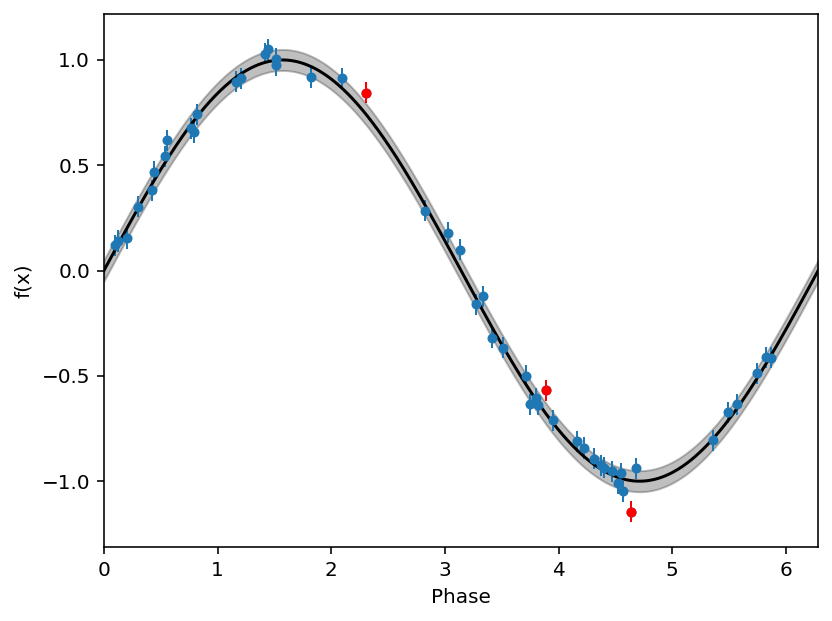

In [29]:
plot_sine_measurements()

# Exercise 2
- Create an array of 200 $x$ values from -10 to 10.
- Define a quadratic function $y=ax^2+bx+c$. For example, use $a=1$, $b=2$, $c=3$.
- Add random noise to the y values to simulate measurement errors, you can use $\mu=0$ and $\sigma=5$.

- Plot these values as a scatter plot with errorbars, with the an expected error of 5 as an observation-SD band around the true function.

The shaded plus/minus-observation-SD band illustrates expected measurement spread around the reference curve. It does not estimate uncertainty in fitted parameters. The exercise below deliberately distinguishes a known noise scale from the realised noise of an individual point.

In [30]:
def plot_random_quadratic():
    """
    Plots the quadratic with measurement noise
    """
    return

In [31]:
plot_random_quadratic()

## End Exercise 2

To finish, let's think about combining distributions and correlations with pair plots/ corner plots.

In [32]:
x = rng.choice(np.linspace(-100, 100, 400), 400)
x2 = rng.uniform(-150, 50, 400)
x3 = rng.normal(25, 100, 400)
y1 = x * rng.normal(2, 0.2, x.size)
y2 = x * rng.normal(2, 0.1, x.size) + x3
y3 = x2 / rng.normal(2, 0.4, x2.size) - rng.normal(0, 5, x2.size)
df = pd.DataFrame(data=dict(x=x, x2=x2, x3=x3, y1=y1, y2=y2, y3=y3))
df.corr()

,x,x2,x3,y1,y2,y3
x,1.000000,-0.025534,0.057148,0.994402,0.777261,-0.039691
x2,-0.025534,1.000000,-0.057351,-0.024443,-0.051704,0.938765
x3,0.057148,-0.057351,1.000000,0.057033,0.671432,-0.027361
y1,0.994402,-0.024443,0.057033,1.000000,0.773289,-0.036414
y2,0.777261,-0.051704,0.671432,0.773289,1.000000,-0.042565
y3,-0.039691,0.938765,-0.027361,-0.036414,-0.042565,1.000000


In [33]:
def plot_pairplot(data):
    """
    Create a pairplot of some random correlated data
    """
    sns.pairplot(data, corner=True)
    plt.show()
    return

In [34]:
%pip install corner

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [35]:
import corner

In [36]:
from corner import corner  # installed in the documented teaching environment

In [37]:
def plot_cornerplot(data):
    """
    Create a corner plot
    """
    fig = corner(data, show_titles=True, quantiles=[0.25, 0.5, 0.75], labels=data.columns,
                 plot_contours=False, plot_density=False)
    plt.show()
   
    return fig

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

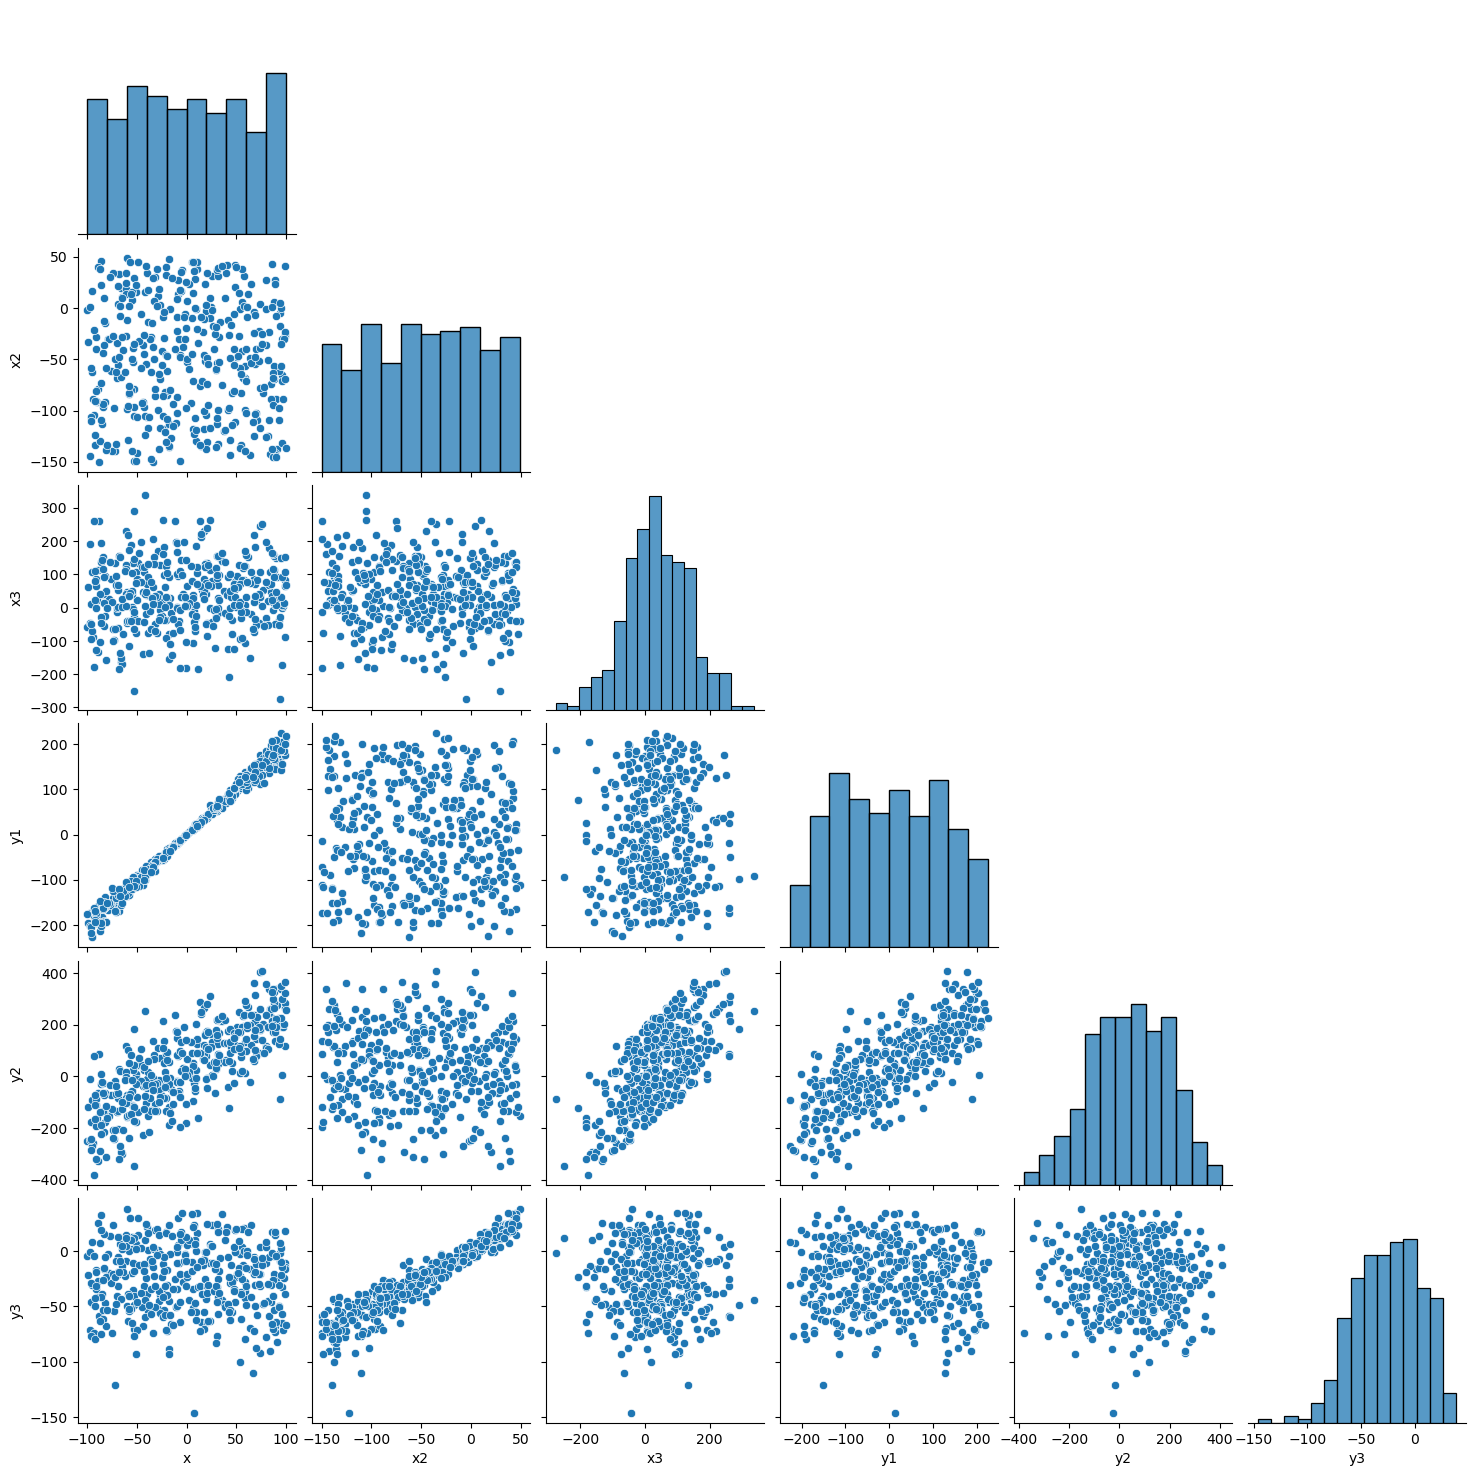

In [39]:
plot_pairplot(df)

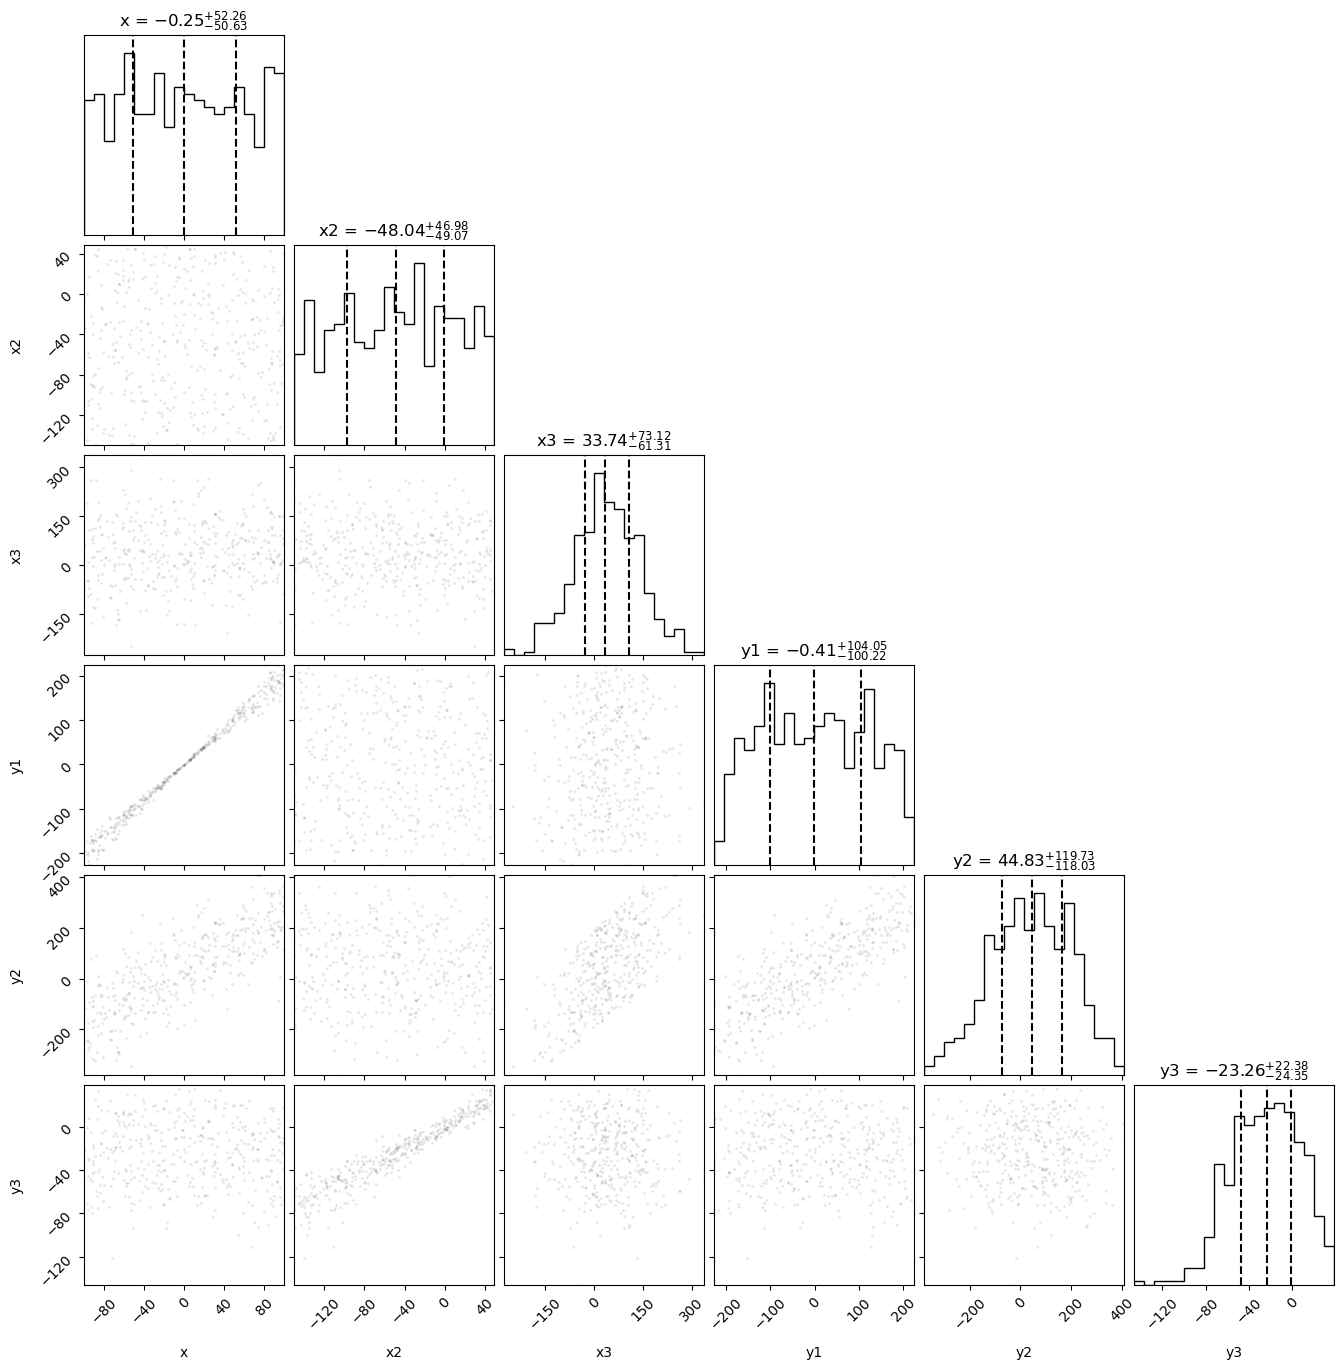

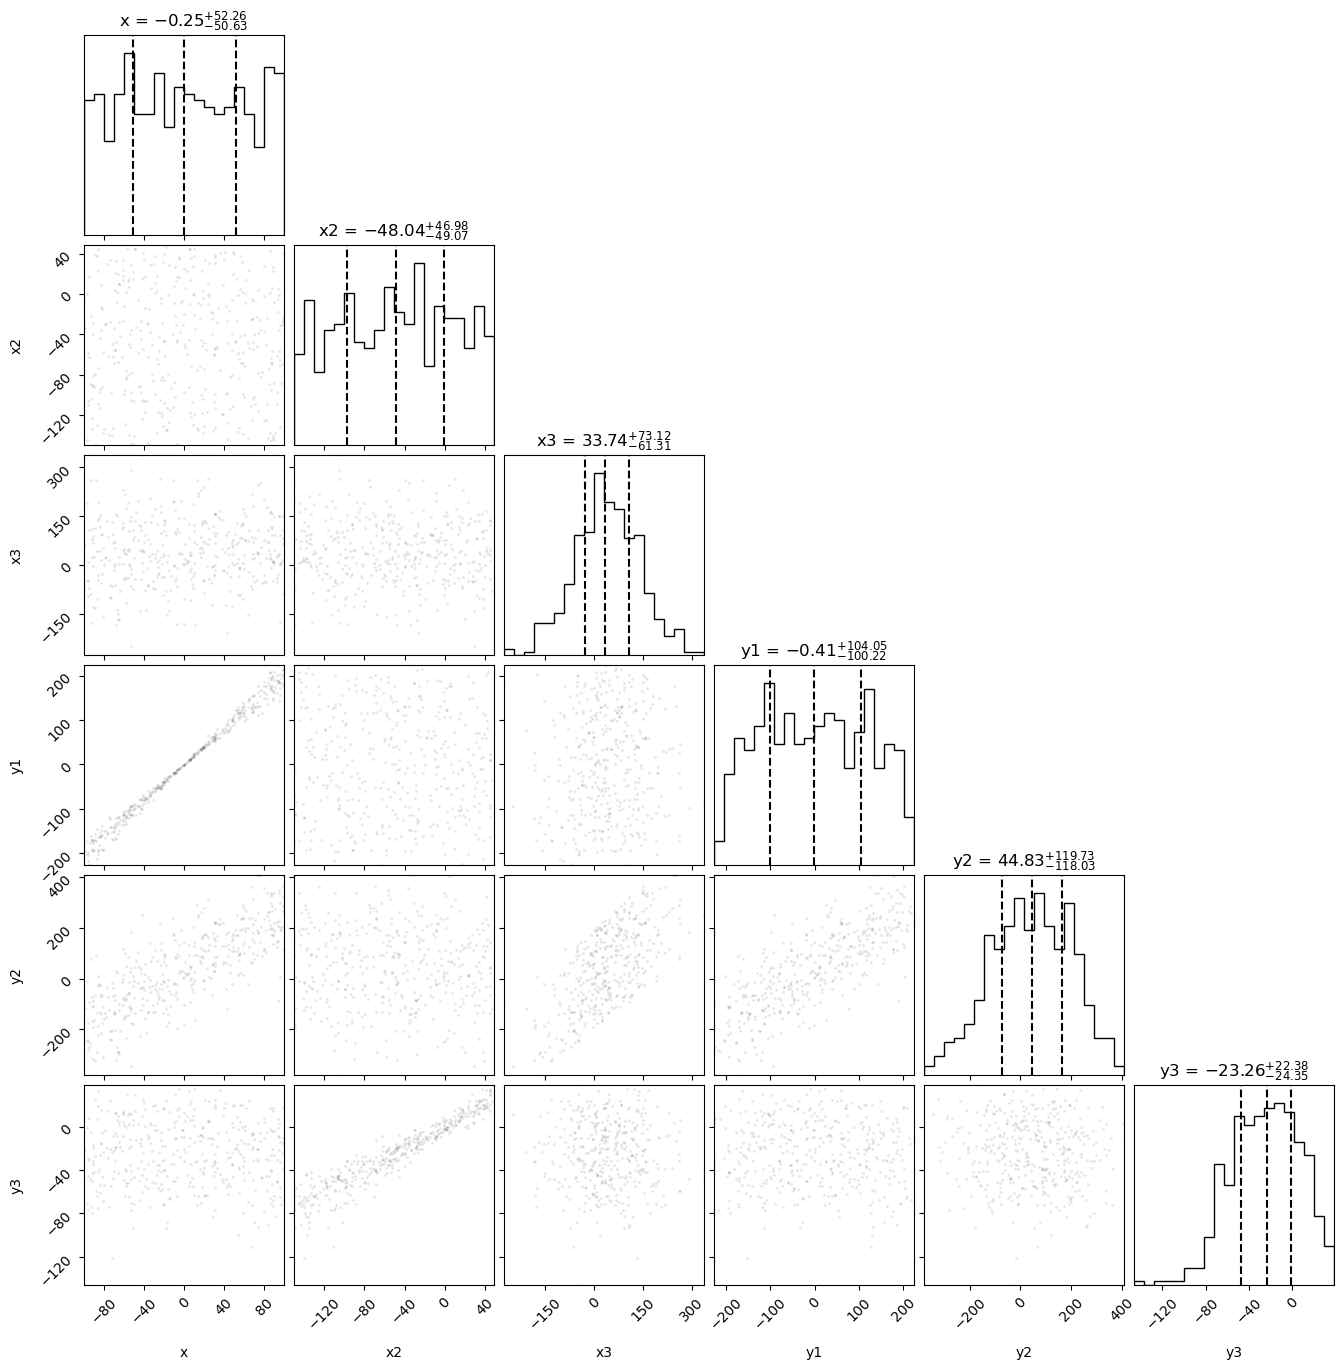

In [40]:
plot_cornerplot(df)

# Exercise 3
Use the two samples below and plot them separately as a pair plot and a corner plot. Describe one difference between the results.

In [22]:
uncorrelated_data = rng.normal(size=(100, 3))
df_uncorrelated = pd.DataFrame(uncorrelated_data, columns=['X', 'Y', 'Z'])

mean = rng.uniform(size=3)
random_matrix = rng.random((3, 3))
cov = np.dot(random_matrix, random_matrix.T)
correlated_data = rng.multivariate_normal(mean, cov, size=100)
df_correlated = pd.DataFrame(correlated_data, columns=['X', 'Y', 'Z'])

## End Exercise 3

## Check your understanding
- How does a commit differ from a push?
- What do your error bars represent?
- Which relationships can you see in the pair plots?

In [23]:
import os

os.chdir(r"C:\Users\by26aac\Version-Control")

print(os.getcwd())

C:\Users\by26aac\Version-Control


In [41]:
!git status

On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [42]:
import os

print(os.getcwd())

C:\Users\by26aac\Version-Control
